# Погрешности и корни уравнений / 误差与方程求根

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#E07A25", "#2B8A6E", "#A64B78"]),
})
from scipy.optimize import root_scalar

## 1. Числа с плавающей точкой / 浮点数
Десятичные числа хранятся приближённо. Для сравнения задаём допустимое отклонение.

十进制数在计算机中通常只能近似表示。比较浮点数时，需要指定允许的误差。

In [2]:
value = 0.1 + 0.2
print(value)
print(value == 0.3)
print(np.isclose(value, 0.3, rtol=0, atol=1e-15))
print("float64 epsilon:", np.finfo(np.float64).eps)

0.30000000000000004
False
True
float64 epsilon: 2.220446049250313e-16


## 2. Абсолютная и относительная погрешность / 绝对误差与相对误差
Для приближения $x$ к известному $x_*$: $E=|x-x_*|$, $\delta=E/|x_*|$.
При $x_*=0$ относительная погрешность в таком виде не определена.

已知参考值 $x_*$ 时，绝对误差为 $E=|x-x_*|$，相对误差为 $\delta=E/|x_*|$。
当参考值为零时，不能使用这个相对误差公式。

In [3]:
exact_root = np.sqrt(2.0)
approx_root = 1.4142
absolute_error = abs(approx_root - exact_root)
relative_error = absolute_error / abs(exact_root)
print("Абсолютная / 绝对误差:", absolute_error)
print("Относительная / 相对误差:", relative_error)

Абсолютная / 绝对误差: 1.3562373095243885e-05
Относительная / 相对误差: 9.590045984628936e-06


## 3. Задача поиска корня / 求根问题
Найдём положительный корень $f(x)=x^2-2$ на $[1,2]$. Он равен $\sqrt{2}$.

求 $f(x)=x^2-2$ 在 $[1,2]$ 内的正根，参考值为 $\sqrt{2}$。

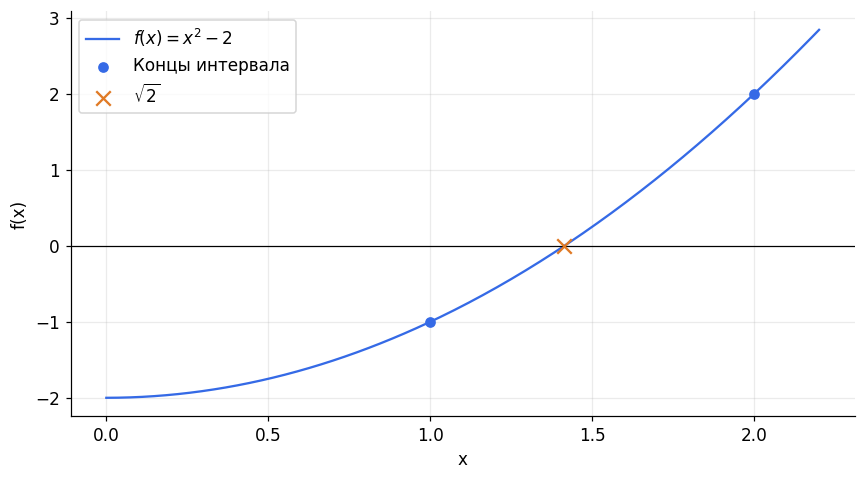

In [4]:
f = lambda x: x**2 - 2
df = lambda x: 2*x
xx = np.linspace(0, 2.2, 300)
fig, ax = plt.subplots()
ax.plot(xx, f(xx), label=r"$f(x)=x^2-2$")
ax.axhline(0, color="black", linewidth=0.8)
ax.scatter([1, 2], [f(1), f(2)], label="Концы интервала", zorder=3)
ax.scatter([exact_root], [0], marker="x", s=90, label=r"$\sqrt{2}$", zorder=4)
ax.set(xlabel="x", ylabel="f(x)")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Метод бисекции / 二分法
Для непрерывной функции выбираем интервал со сменой знака. На каждом шаге оставляем половину интервала, содержащую корень. `tol` ограничивает половину ширины конечного интервала.

对连续函数选择两端异号的区间，每一步保留含根的一半。`tol` 控制最终区间的半宽。

In [5]:
def bisection(f, a, b, tol=1e-8):
    if not (a < b and tol > 0):
        raise ValueError("Require a < b and tol > 0")
    if f(a) == 0: return a
    if f(b) == 0: return b
    if f(a) * f(b) > 0:
        raise ValueError("No sign change on [a, b]")
    while (b - a) / 2 > tol:
        c = (a + b) / 2
        if f(a) * f(c) <= 0:
            b = c
        else:
            a = c
    return (a + b) / 2

In [6]:
root_bisect = bisection(f, 1.0, 2.0)
print("Корень / 根:", root_bisect)
print("Невязка / 残差:", f(root_bisect))
print("Ошибка / 误差:", abs(root_bisect - exact_root))

Корень / 根: 1.4142135605216026
Невязка / 残差: -5.236811428943611e-09
Ошибка / 误差: 1.8514925148593875e-09


## 5. Метод Ньютона / 牛顿法
Начинаем с `x0 = 1.5` и используем производную `df`. Малое изменение аргумента само по себе не гарантирует малую невязку: после остановки проверяем также `f(root)`.

从 `x0 = 1.5` 出发，使用导数 `df` 迭代。相邻迭代值变化很小，并不一定表示残差很小，因此还需检查 `f(root)`。

In [7]:
def newton(f, df, x0, tol=1e-8, max_iter=100):
    x = x0
    for _ in range(max_iter):
        if f(x) == 0: return x
        if df(x) == 0:
            raise ValueError("Zero derivative")
        x_new = x - f(x) / df(x)
        if abs(x_new - x) < tol:
            return x_new
        x = x_new
    raise RuntimeError("No convergence")

In [8]:
root_newton = newton(f, df, 1.5)
print("Корень / 根:", root_newton)
print("Невязка / 残差:", f(root_newton))
print("Ошибка / 误差:", abs(root_newton - exact_root))

Корень / 根: 1.4142135623730951
Невязка / 残差: 4.440892098500626e-16
Ошибка / 误差: 0.0


## 6. Как меняется приближение / 近似解如何变化
Запишем промежуточные значения для того же примера. У бисекции показываем середины интервалов, у Ньютона — последовательность приближений, начиная с `x0`.

记录同一例题的中间结果。二分法显示区间中点；牛顿法显示从 `x0` 开始的近似解序列。

In [9]:
left, right = 1.0, 2.0
bisect_history = [(left + right) / 2]
while (right - left) / 2 > 1e-8:
    middle = (left + right) / 2
    if f(left) * f(middle) <= 0:
        right = middle
    else:
        left = middle
    bisect_history.append((left + right) / 2)

newton_history = [1.5]
for _ in range(100):
    current = newton_history[-1]
    if f(current) == 0:
        break
    following = current - f(current) / df(current)
    newton_history.append(following)
    if abs(following - current) < 1e-8:
        break

print("Бисекция: первые 6 и последнее / 二分法：前 6 项和最后一项")
print(np.array(bisect_history[:6]))
print(bisect_history[-1])
print("Ньютон / 牛顿法:")
print(np.array(newton_history))

Бисекция: первые 6 и последнее / 二分法：前 6 项和最后一项
[1.5      1.25     1.375    1.4375   1.40625  1.421875]
1.4142135605216026
Ньютон / 牛顿法:
[1.5        1.41666667 1.41421569 1.41421356 1.41421356]


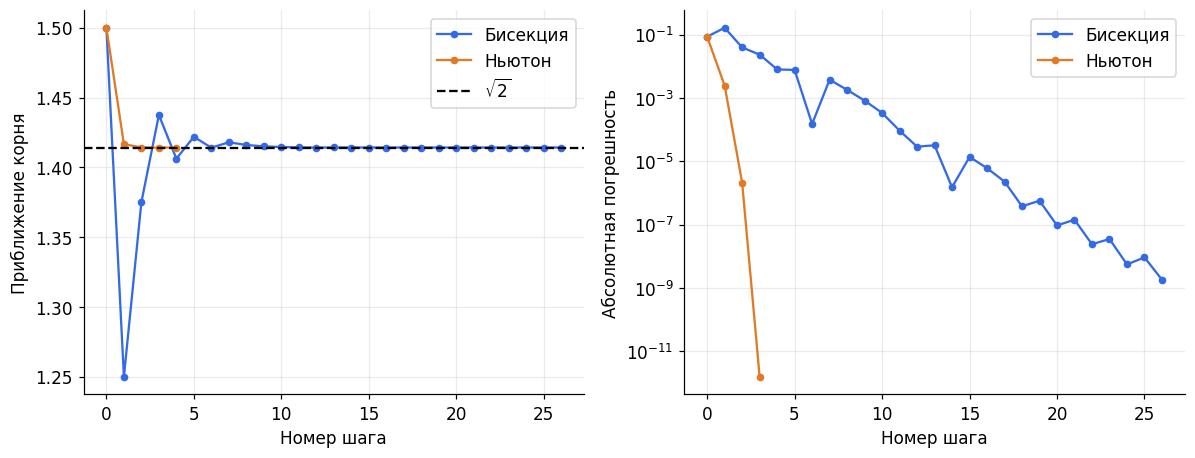

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for history, label in [(bisect_history, "Бисекция"), (newton_history, "Ньютон")]:
    iterations = np.arange(len(history))
    errors = np.abs(np.asarray(history) - exact_root)
    axes[0].plot(iterations, history, "o-", markersize=4, label=label)
    positive = errors > 0
    axes[1].semilogy(iterations[positive], errors[positive], "o-", markersize=4, label=label)
axes[0].axhline(exact_root, color="black", linestyle="--", label=r"$\sqrt{2}$")
axes[0].set(xlabel="Номер шага", ylabel="Приближение корня")
axes[1].set(xlabel="Номер шага", ylabel="Абсолютная погрешность")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

Нулевую ошибку нельзя показать на логарифмической оси; такие точки пропущены. Здесь Ньютон сходится быстрее, но скорость и сходимость зависят от функции и начального приближения.

零误差不能显示在对数坐标轴上，因此跳过这些点。本例中牛顿法更快，但收敛速度和是否收敛取决于函数及初值。

## 7. Сравнение с SciPy / 与 SciPy 比较
`root_scalar` возвращает корень и информацию о сходимости. Ошибка относительно известного корня и невязка — разные величины.

`root_scalar` 返回根及收敛信息。相对于已知根的误差与函数残差是不同的量。

In [11]:
scipy_bisect = root_scalar(f, bracket=[1, 2], method="bisect", xtol=1e-8)
scipy_newton = root_scalar(f, fprime=df, x0=1.5, method="newton", xtol=1e-8)
print(f"{'Method':<18} {'Root':>16} {'|f(root)|':>13} {'Error':>13}")
for name, result in [("Bisection", root_bisect), ("Newton", root_newton),
                     ("SciPy bisect", scipy_bisect.root), ("SciPy Newton", scipy_newton.root)]:
    print(f"{name:<18} {result:16.10f} {abs(f(result)):13.3e} {abs(result-exact_root):13.3e}")
print("SciPy converged:", scipy_bisect.converged, scipy_newton.converged)

Method                         Root     |f(root)|         Error
Bisection              1.4142135605     5.237e-09     1.851e-09
Newton                 1.4142135624     4.441e-16     0.000e+00
SciPy bisect           1.4142135605     5.237e-09     1.851e-09
SciPy Newton           1.4142135624     4.441e-16     0.000e+00
SciPy converged: True True


## 8. Условия применимости / 适用条件
На интервале `[2, 3]` нет смены знака для этого примера. В точке `x0 = 0` производная равна нулю. Покажем сообщения, не прерывая выполнение Notebook.

本例在 `[2, 3]` 上没有变号；在 `x0 = 0` 处导数为零。下面捕获并显示这些错误，不中断 Notebook。

In [12]:
try:
    bisection(f, 2.0, 3.0)
except ValueError as error:
    print("Бисекция / 二分法:", error)

try:
    newton(f, df, 0.0)
except ValueError as error:
    print("Ньютон / 牛顿法:", error)

Бисекция / 二分法: No sign change on [a, b]
Ньютон / 牛顿法: Zero derivative


## 9. Пример: $x^3-x-1=0$ / 例题：$x^3-x-1=0$
Используем интервал $[1,2]$ и начальное приближение $1.5$. Точное значение корня заранее не подставляем; сравниваем методы и невязки.

使用区间 $[1,2]$ 和初值 $1.5$。不预先代入精确根，比较不同方法的结果和残差。

In [13]:
g = lambda x: x**3 - x - 1
dg = lambda x: 3*x**2 - 1
cubic_bisect = bisection(g, 1.0, 2.0)
cubic_newton = newton(g, dg, 1.5)
cubic_reference = root_scalar(g, bracket=[1, 2], method="brentq").root
for name, result in [("Bisection", cubic_bisect), ("Newton", cubic_newton), ("SciPy brentq", cubic_reference)]:
    print(f"{name:14s}: x = {result:.10f}, f(x) = {g(result):.3e}")

Bisection     : x = 1.3247179613, f(x) = 1.709e-08
Newton        : x = 1.3247179572, f(x) = 2.220e-16
SciPy brentq  : x = 1.3247179572, f(x) = 2.220e-16
